# 01 – G50T automatic solver

Finds a short winning action sequence for every level by **breadth-first search** on copies of the game.
Output: `solutions/g50t_solutions.json` – the list of actions per level. Later notebooks replay these to build the dataset.

Run it in the same folder as notebook 00 (it reuses the downloaded `environment_files`).
Start with level 1 only (`LEVELS_TO_SOLVE = [0]`) to check that it works, then run all.

In [1]:
%pip install -q "arc-agi==0.9.9" pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-11-13 01:54:49 | INFO | Created new scorecard: bd97a3f9-d1d8-4128-8475-222f2e728c3b
2026-11-13 01:54:49 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)
2026-11-13 01:54:49 | INFO | Successfully loaded game class G50t from environment_files/g50t/5849a774/g50t.py
levels: 7 | state: NOT_FINISHED


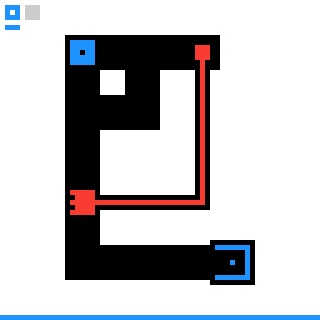

In [2]:
import copy, json, pickle, time, zlib
from collections import deque
from pathlib import Path

import numpy as np
import arc_agi
from arc_agi import OperationMode
from arc_agi.rendering import frame_to_rgb_array
from PIL import Image
from IPython.display import display

ENV_DIR = "./environment_files"
GAME_ID = "g50t"
ACTION_NAMES = ["ACTION1", "ACTION2", "ACTION3", "ACTION4", "ACTION5"]   # up, down, left, right, rewind
OUT = Path("solutions"); OUT.mkdir(exist_ok=True)

arcade = arc_agi.Arcade(operation_mode=OperationMode.OFFLINE, environments_dir=ENV_DIR)

def new_env():
    env = arcade.make(GAME_ID)
    return env, env.reset()

def act(env, name):
    return env.step({a.name: a for a in env.action_space}[name])

def render(obs, scale=8):
    return Image.fromarray(frame_to_rgb_array(steps=0, frame=obs.frame[-1], scale=scale))

env, obs = new_env()
print("levels:", obs.win_levels, "| state:", obs.state.name)
display(render(obs, 5))

## Find the internal game object
Lets the solver read hidden state (how many moves were recorded for the ghost) instead of only pixels.

In [3]:
def find_attr_path(obj, target="vgwycxsxjz", depth=0, path=()):
    if hasattr(obj, target):
        return path
    if depth >= 3 or not hasattr(obj, "__dict__"):
        return None
    for name, value in vars(obj).items():
        if isinstance(value, (int, float, str, bytes, list, dict, tuple, np.ndarray)) or value is None:
            continue
        found = find_attr_path(value, target, depth + 1, path + (name,))
        if found is not None:
            return found
    return None

GAME_PATH = find_attr_path(env)
print("path to game object:", GAME_PATH)

def get_world(e):
    if GAME_PATH is None:
        return None
    g = e
    for name in GAME_PATH:
        g = getattr(g, name)
    return g.vgwycxsxjz

path to game object: ('_game',)


## State key + snapshot helpers
* The key ignores the **bottom row** (the step-budget bar), otherwise every state would look new.
* While ghosts are replaying, the key also includes the time index, because the ghosts' future moves depend on it.
* The key includes the ghosts' recorded paths: two screens can look identical but have ghosts that will do different things.
* Game copies are stored compressed to save RAM.

In [4]:
def state_key(e, o):
    frame = np.asarray(o.frame[-1])[:63]          # drop step-budget bar (row 63)
    w = get_world(e)
    extra = None
    if w is not None:
        ghost_len = max((len(p) for p in w.rloltuowth.values()), default=0)
        t = len(w.areahjypvy)
        ghost_paths = tuple(tuple(p) for p in w.rloltuowth.values())   # invisible on screen, but decides what ghosts do
        extra = (t if t < ghost_len else -1, len(w.rloltuowth), w.rlazdofsxb, ghost_paths)
    return frame.tobytes(), extra

# make the game class picklable (it is loaded from a file, not a normal module)
import sys, types
_game_cls = type(get_world(env).hejgkplfbj)
_mod_name = _game_cls.__module__
if _mod_name not in sys.modules:
    _mod = types.ModuleType(_mod_name)
    _mod.__dict__.update(_game_cls.__init__.__globals__)
    sys.modules.setdefault(_mod_name.split(".")[0], types.ModuleType(_mod_name.split(".")[0]))
    sys.modules[_mod_name] = _mod

try:
    blob = zlib.compress(pickle.dumps(env, protocol=5), 3)
    pickle.loads(zlib.decompress(blob))
    USE_PICKLE = True
    print(f"one compressed game snapshot = {len(blob)/1024:.1f} KB")
except Exception as ex:
    USE_PICKLE = False
    print("pickle not possible, falling back to deepcopy:", repr(ex))

def snapshot(e):
    return zlib.compress(pickle.dumps(e, protocol=5), 3) if USE_PICKLE else copy.deepcopy(e)

def restore(s):
    return pickle.loads(zlib.decompress(s)) if USE_PICKLE else copy.deepcopy(s)

pickle not possible, falling back to deepcopy: ValueError('0 is not a valid GameAction')


## Breadth-first search for one level

In [5]:
def solve_level(start_env, start_obs, max_nodes=400_000, time_limit=1800):
    """Return the shortest action list that completes the current level (or None)."""
    level0 = start_obs.levels_completed
    queue = deque([(snapshot(start_env), [])])
    seen = {state_key(start_env, start_obs)}
    t0, expanded = time.time(), 0
    while queue:
        snap, path = queue.popleft()
        expanded += 1
        if expanded % 2000 == 0:
            print(f"  expanded {expanded:,} | queue {len(queue):,} | depth {len(path)} | {time.time()-t0:.0f}s")
        if expanded > max_nodes or time.time() - t0 > time_limit:
            print("  limit reached -> no solution found")
            return None
        for name in ACTION_NAMES:
            e = restore(snap)
            o = act(e, name)
            if o is None:
                continue
            if o.levels_completed > level0 or o.state.name == "WIN":
                print(f"  solved: {len(path)+1} actions, {expanded:,} states, {time.time()-t0:.0f}s")
                return path + [name]
            if o.state.name == "GAME_OVER":
                continue
            k = state_key(e, o)
            if k in seen:
                continue
            seen.add(k)
            queue.append((snapshot(e), path + [name]))
    print("  search space exhausted -> no solution")
    return None

## Quick check: known level 1 solution must win

In [6]:
env, obs = new_env()
for name in ["ACTION4"]*4 + ["ACTION5"] + ["ACTION2"]*7 + ["ACTION4"]*5:
    obs = act(env, name)
print("levels completed:", obs.levels_completed, "(should be 1)")

2026-11-13 01:54:49 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)
levels completed: 1 (should be 1)


## Solve the levels
Test with `[0]` first. Then set `LEVELS_TO_SOLVE = list(range(7))`. Results are saved after every level, so you can stop and continue.

In [15]:
LEVELS_TO_SOLVE = list(range(7))          # first test level 1 only; later: list(range(7))

sol_file = OUT / "g50t_solutions.json"
solutions = json.loads(sol_file.read_text()) if sol_file.exists() else {}

env, obs = new_env()
for lvl in range(max(LEVELS_TO_SOLVE) + 1):
    key = str(lvl)
    if key not in solutions and lvl in LEVELS_TO_SOLVE:
        print(f"Level {lvl+1}: searching ...")
        path = solve_level(env, obs)
        if path is None:
            print(f"Level {lvl+1}: FAILED - we will record this level by hand"); break
        solutions[key] = path
        sol_file.write_text(json.dumps(solutions, indent=1))
    if key not in solutions:
        break
    for name in solutions[key]:            # replay to reach the next level
        obs = act(env, name)
    print(f"Level {lvl+1}: {len(solutions[key])} actions -> levels completed = {obs.levels_completed}")

print({k: len(v) for k, v in solutions.items()})

2026-11-13 02:38:38 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)
Level 1: 17 actions -> levels completed = 1
Level 2: 31 actions -> levels completed = 2
Level 3: 64 actions -> levels completed = 3
Level 4: searching ...


KeyboardInterrupt: 

## Watch a solution (sanity check)

2026-11-13 01:54:55 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)


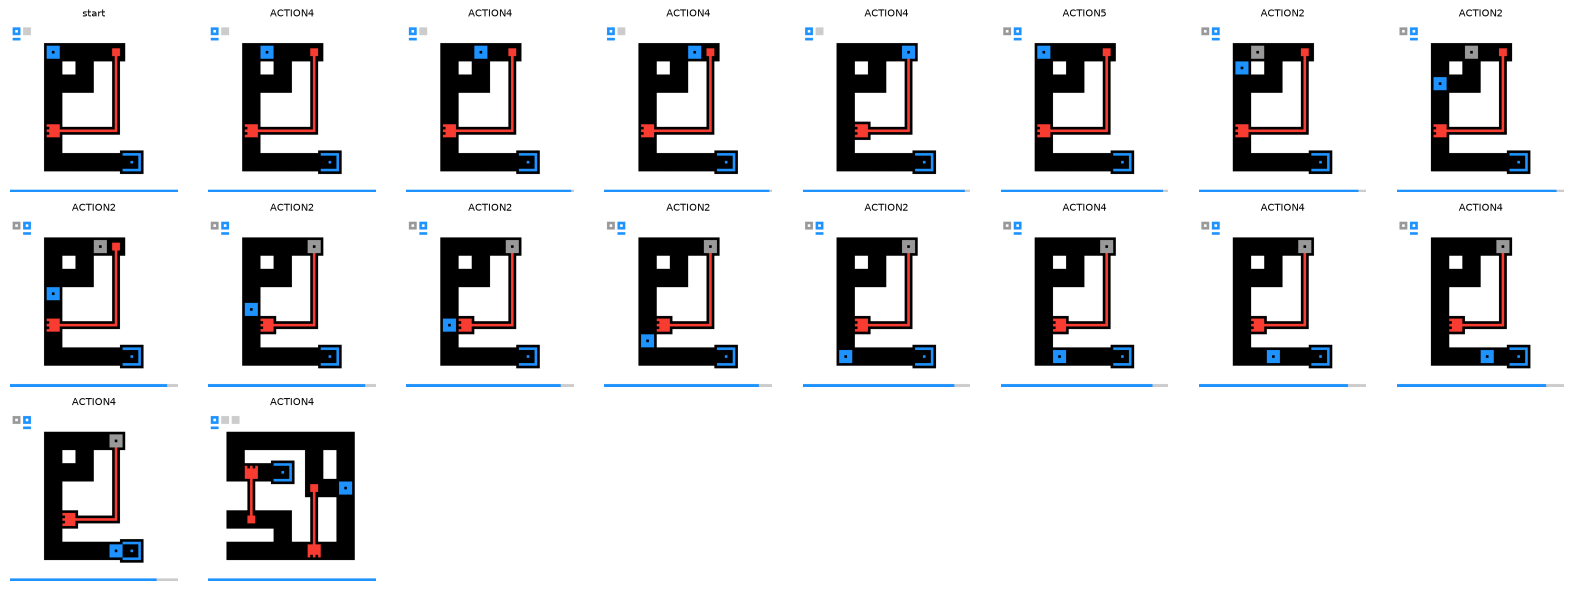

In [8]:
import matplotlib.pyplot as plt

def show_solution(level, every=1):
    env, obs = new_env()
    for l in range(level):
        for name in solutions[str(l)]:
            obs = act(env, name)
    frames = [render(obs, 4)]
    for i, name in enumerate(solutions[str(level)]):
        obs = act(env, name)
        if i % every == 0:
            frames.append(render(obs, 4))
    cols = 8
    rows = (len(frames) + cols - 1) // cols
    plt.figure(figsize=(cols * 2, rows * 2))
    for i, f in enumerate(frames):
        plt.subplot(rows, cols, i + 1); plt.imshow(f); plt.axis("off")
        plt.title("start" if i == 0 else solutions[str(level)][(i - 1) * every], fontsize=7)
    plt.tight_layout(); plt.show()
    frames[0].save(OUT / f"level{level+1}_solution.gif", save_all=True, append_images=frames[1:], duration=250, loop=0)

show_solution(0)

2026-11-13 02:26:54 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)
Level 2 ready


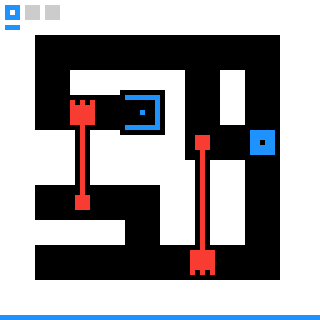

In [10]:
KEYS = {"w": "ACTION1", "s": "ACTION2", "a": "ACTION3", "d": "ACTION4", "r": "ACTION5"}  # up, down, left, right, rewind

def start_level(level):              # level 1 = start_level(0), level 2 = start_level(1), ...
    global play_env, play_obs, play_moves, play_level
    play_env, play_obs = new_env()
    for l in range(level):           # replay the saved solutions to get to this level
        for name in solutions[str(l)]:
            play_obs = act(play_env, name)
    play_moves, play_level = [], level
    print(f"Level {level+1} ready"); display(render(play_obs, 5))

def play(keys):
    global play_obs
    for ch in keys.replace(" ", "").lower():
        if ch not in KEYS:
            print("ignored:", ch); continue
        play_obs = act(play_env, KEYS[ch]); play_moves.append(KEYS[ch])
        if play_obs.levels_completed > play_level:
            solutions[str(play_level)] = list(play_moves)
            sol_file.write_text(json.dumps(solutions, indent=1))
            print(f"LEVEL {play_level+1} SOLVED in {len(play_moves)} moves - saved!")
            display(render(play_obs, 5)); return
        if play_obs.state.name == "GAME_OVER":
            print("GAME OVER - use undo(5) or start_level again")
            break
    print(len(play_moves), "moves so far"); display(render(play_obs, 5))

def undo(n=1):                       # take back the last n moves
    moves = play_moves[:-n]
    start_level(play_level)
    if moves:
        play("".join(k for m in moves for k, v in KEYS.items() if v == m))

start_level(1)   # level 2

LEVEL 2 SOLVED in 31 moves - saved!


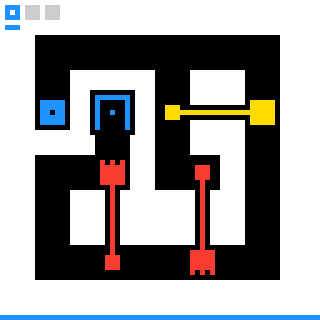

In [12]:
play("aarssssaaaawwaarwwwaaaaaaassddd")

2026-11-13 02:30:17 | INFO | Found latest version of g50t: g50t-5849a774 (downloaded: 2026-11-13 01:16:30.629856+00:00)
Level 3 ready


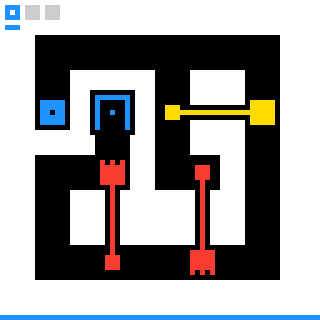

In [13]:
start_level(2)

LEVEL 3 SOLVED in 64 moves - saved!


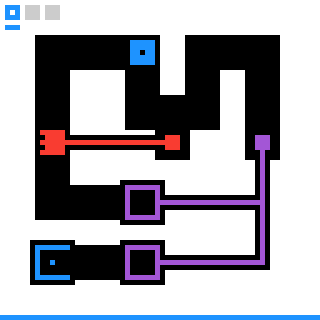

In [14]:
play("wwddddssssdrwwdddddddsssssssaaaaarwwdddddddsssssssaaaaaaawwwddww")